## 1. Load the data

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score


In [20]:

pd.set_option("display.max_columns", 50)

In [28]:
url = "https://raw.githubusercontent.com/rashakil-ds/Public-Datasets/refs/heads/main/Bank%20Data.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(50000, 27)


,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance
0,0x160a,CUS_0xd40,September,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,2022.0,Good,809.98,35.030402,22 Years and 9 Months,No,49.574949,236.64268203272135,Low_spent_Small_value_payments,186.26670208571772
1,0x160b,CUS_0xd40,October,Aaron Maashoh,24,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,9,13.27,4.0,Good,809.98,33.053114,22 Years and 10 Months,No,49.574949,21.465380264657146,High_spent_Medium_value_payments,361.44400385378196
2,0x160c,CUS_0xd40,November,Aaron Maashoh,24,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,4,12.27,4.0,Good,809.98,33.811894,NaN,No,49.574949,148.23393788500925,Low_spent_Medium_value_payments,264.67544623342997
3,0x160d,CUS_0xd40,December,Aaron Maashoh,24_,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",4,5,11.27,4.0,Good,809.98,32.430559,23 Years and 0 Months,No,49.574949,39.08251089460281,High_spent_Medium_value_payments,343.82687322383634
4,0x1616,CUS_0x21b1,September,Rick Rothackerj,28,004-07-5839,_______,34847.84,3037.986667,2,4,6,1,Credit-Builder Loan,3,1,5.42,5.0,Good,605.03,25.926822,27 Years and 3 Months,No,18.816215,39.684018417945296,High_spent_Large_value_payments,485.2984336755923


## 2. Inspect the dataset

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 27 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        50000 non-null  object 
 1   Customer_ID               50000 non-null  object 
 2   Month                     50000 non-null  object 
 3   Name                      44985 non-null  object 
 4   Age                       50000 non-null  object 
 5   SSN                       50000 non-null  object 
 6   Occupation                50000 non-null  object 
 7   Annual_Income             50000 non-null  object 
 8   Monthly_Inhand_Salary     42502 non-null  float64
 9   Num_Bank_Accounts         50000 non-null  int64  
 10  Num_Credit_Card           50000 non-null  int64  
 11  Interest_Rate             50000 non-null  int64  
 12  Num_of_Loan               50000 non-null  object 
 13  Type_of_Loan              44296 non-null  object 
 14  Delay_

In [30]:
missing = df.isna().sum().sort_values(ascending=False)
missing[missing > 0].head(15)

,0
Monthly_Inhand_Salary,7498
Type_of_Loan,5704
Name,5015
Credit_History_Age,4470
Num_of_Delayed_Payment,3498
Amount_invested_monthly,2271
Num_Credit_Inquiries,1035
Monthly_Balance,562


In [31]:
df["Credit_Mix"].value_counts(dropna=False)

,count
Credit_Mix,
Standard,18379
Good,12260
_,9805
Bad,9556


In [32]:
target = "Credit_Mix"
numeric_cols = [
    "Age", "Annual_Income", "Monthly_Inhand_Salary",
    "Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate",
    "Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment",
    "Changed_Credit_Limit", "Num_Credit_Inquiries", "Outstanding_Debt",
    "Credit_Utilization_Ratio", "Total_EMI_per_month",
    "Amount_invested_monthly", "Monthly_Balance"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace("_", "", regex=False),
        errors="coerce"
    )

In [33]:
history = df["Credit_History_Age"].astype(str).str.extract(
    r"(\d+)\s*Years?\s*and\s*(\d+)\s*Months?"
)

In [35]:
df["Credit_History_Months"] = (
    pd.to_numeric(history[0], errors="coerce") * 12
    + pd.to_numeric(history[1], errors="coerce")
)

In [36]:
for col in ["Occupation", "Payment_of_Min_Amount", "Payment_Behaviour"]:
    df[col] = df[col].replace(["_", "NM"], np.nan)

In [37]:
df[target] = df[target].where(df[target].isin(["Bad", "Standard", "Good"]))
df = df.dropna(subset=[target]).copy()

In [38]:
df.shape

(40195, 28)

In [39]:
df = df.drop(columns=["ID", "Name", "SSN", "Credit_History_Age"], errors="ignore")

In [40]:
print(df.shape)
df[target].value_counts()

(40195, 24)


,count
Credit_Mix,
Standard,18379
Good,12260
Bad,9556


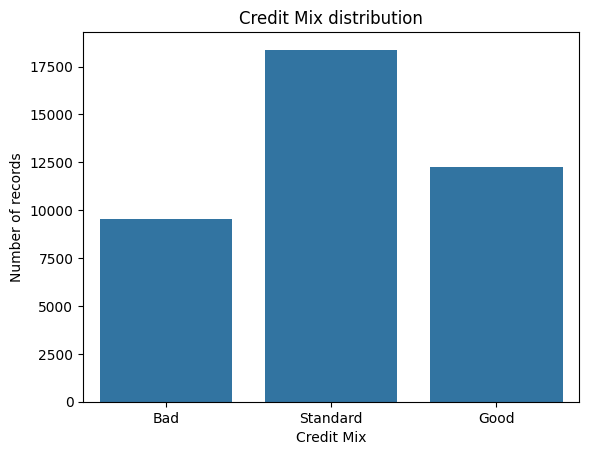

In [44]:
sns.countplot(data=df, x="Credit_Mix", order=["Bad", "Standard", "Good"])
plt.title("Credit Mix distribution")
plt.xlabel("Credit Mix")
plt.ylabel("Number of records")
plt.show()

In [45]:
df.groupby("Credit_Mix")[[
    "Outstanding_Debt", "Interest_Rate", "Num_of_Delayed_Payment",
    "Credit_Utilization_Ratio"
]].median().round(2)

,Outstanding_Debt,Interest_Rate,Num_of_Delayed_Payment,Credit_Utilization_Ratio
Credit_Mix,,,,
Bad,2845.28,25.0,20.0,31.67
Good,733.76,6.0,7.0,32.78
Standard,1013.53,15.0,14.0,32.32


## 5. Select features and split by customer

In [46]:
features = ["Age", "Annual_Income", "Monthly_Inhand_Salary","Num_Bank_Accounts", "Num_Credit_Card", "Interest_Rate","Num_of_Loan", "Delay_from_due_date", "Num_of_Delayed_Payment","Changed_Credit_Limit", "Num_Credit_Inquiries", "Outstanding_Debt",
    "Credit_Utilization_Ratio", "Credit_History_Months","Total_EMI_per_month", "Amount_invested_monthly", "Monthly_Balance","Occupation", "Payment_of_Min_Amount", "Payment_Behaviour"
]

df["Debt_to_Income"] = df["Outstanding_Debt"]/df["Annual_Income"].replace(0, np.nan)
df["EMI_to_Salary"] = df["Total_EMI_per_month"] / df["Monthly_Inhand_Salary"].replace(0, np.nan)
features += ["Debt_to_Income", "EMI_to_Salary"]

In [47]:
df = df.dropna(subset=["Customer_ID"]).copy()
df.shape

(40195, 26)

In [48]:
customer_target = df.groupby("Customer_ID")["Credit_Mix"].agg(lambda s: s.mode().iloc[0])

In [49]:
customer_target

,Credit_Mix
Customer_ID,
CUS_0x1000,Bad
CUS_0x1009,Standard
CUS_0x100b,Good
CUS_0x1011,Standard
CUS_0x1013,Good
...,...
CUS_0xff3,Good
CUS_0xff4,Standard
CUS_0xff6,Good


In [50]:
train_ids, test_ids = train_test_split(customer_target.index,test_size=0.2,random_state=42,stratify=customer_target)

In [51]:
train_df = df[df["Customer_ID"].isin(train_ids)].copy()
test_df = df[df["Customer_ID"].isin(test_ids)].copy()

In [52]:
print(train_df.shape, test_df.shape)

(32114, 26) (8081, 26)


In [53]:
X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

Missing numeric values are filled with the median. Categorical values are filled with the most common value and one-hot encoded. Scaling is useful for Logistic Regression; the same preprocessing is used for both models to keep the comparison simple.

In [54]:
categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
numeric_feature_cols = [col for col in features if col not in categorical_cols]

In [55]:
numeric_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [56]:
categorical_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [57]:
preprocessor = ColumnTransformer([
    ("numeric", numeric_preprocessing, numeric_feature_cols),
    ("categorical", categorical_preprocessing, categorical_cols)
])

In [58]:
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

In [60]:
logistic_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Annual_Income',
                                                   'Monthly_Inhand_Salary',
                                                   'Num_Bank_Accounts',
                                                   'Num_Credit_Card',
                                                   'Interest_Rate',
                                                   'Num_of_Loan',
                                                   'Delay_from_due_date',
                                                   'Num_of_Delayed_Payment',
                                                   'Changed_Credit_Limit...
                                                   'Total_EMI_per_month',
                                                   'Amount_invested_monthly',
                                                   'Monthly_Balance',
                                                   'Debt_to_Income',
                                                   'EMI_to_Salary']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Occupation',
                                                   'Payment_of_Min_Amount',
                                                   'Payment_Behaviour'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [59]:
forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=150,
        max_depth=15,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    ))
])

In [61]:
forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'Annual_Income',
                                                   'Monthly_Inhand_Salary',
                                                   'Num_Bank_Accounts',
                                                   'Num_Credit_Card',
                                                   'Interest_Rate',
                                                   'Num_of_Loan',
                                                   'Delay_from_due_date',
                                                   'Num_of_Delayed_Payment',
                                                   'Changed_Credit_Limit...
                                                   'Monthly_Balance',
                                                   'Debt_to_Income',
                                                   'EMI_to_Salary']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Occupation',
                                                   'Payment_of_Min_Amount',
                                                   'Payment_Behaviour'])])),
                ('model',
                 RandomForestClassifier(class_weight='balanced', max_depth=15,
                                        n_estimators=150, n_jobs=-1,
                                        random_state=42))])

Macro F1 gives equal weight to each class, so it is useful when the class counts are uneven. The test set contains customers that were not used for training.

In [62]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": forest_model
}
results = []

In [63]:
for name, model in models.items():
    predictions = model.predict(X_test)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Macro F1": f1_score(y_test, predictions, average="macro")
    })

results = pd.DataFrame(results).sort_values("Macro F1", ascending=False)
results.round(4)

,Model,Accuracy,Macro F1
1,Random Forest,0.9284,0.9308
0,Logistic Regression,0.8169,0.8232


In [64]:
best_name = results.iloc[0]["Model"]
best_model = models[best_name]
best_predictions = best_model.predict(X_test)

print("Selected model:", best_name)
print(classification_report(y_test, best_predictions, labels=["Bad", "Standard", "Good"], zero_division=0))

Selected model: Random Forest
              precision    recall  f1-score   support

         Bad       0.91      0.98      0.94      1901
    Standard       0.95      0.90      0.92      3699
        Good       0.92      0.94      0.93      2481

    accuracy                           0.93      8081
   macro avg       0.93      0.94      0.93      8081
weighted avg       0.93      0.93      0.93      8081



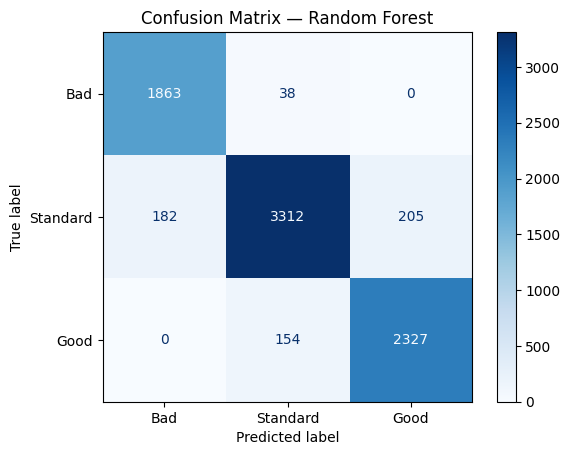

In [65]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=["Bad", "Standard", "Good"],
    cmap="Blues"
)
plt.title(f"Confusion Matrix — {best_name}")
plt.show()

In [66]:
forest_model.fit(X_train, y_train)
encoded_names = forest_model.named_steps["preprocessing"].get_feature_names_out()
importances = forest_model.named_steps["model"].feature_importances_

importance = pd.DataFrame({
    "Feature": encoded_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

importance.head(15)

,Feature,Importance
5,numeric__Interest_Rate,0.144671
11,numeric__Outstanding_Debt,0.115892
3,numeric__Num_Bank_Accounts,0.113114
8,numeric__Num_of_Delayed_Payment,0.099803
35,categorical__Payment_of_Min_Amount_No,0.084450
36,categorical__Payment_of_Min_Amount_Yes,0.080688
7,numeric__Delay_from_due_date,0.072142
6,numeric__Num_of_Loan,0.060411
9,numeric__Changed_Credit_Limit,0.039794
13,numeric__Credit_History_Months,0.029936


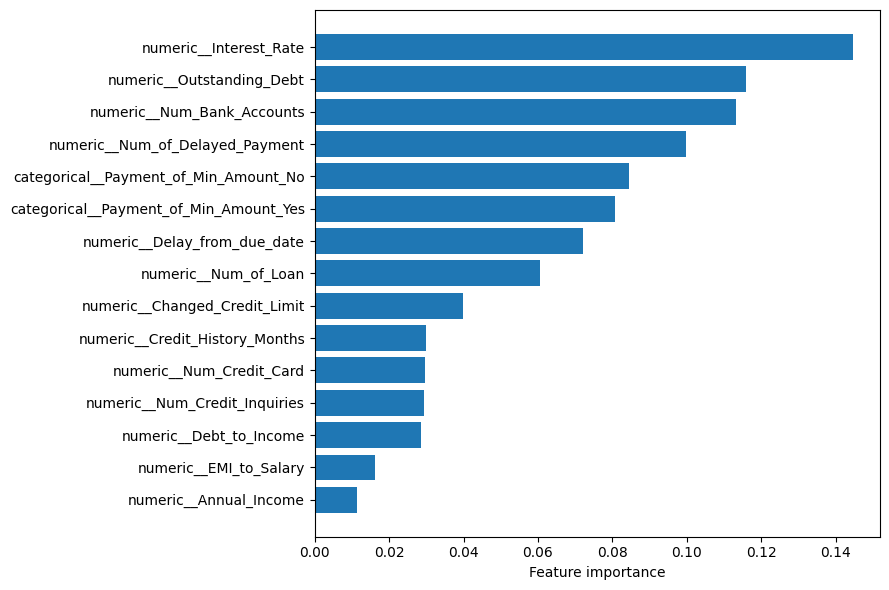

In [68]:
top_features = importance.head(15).sort_values("Importance")
plt.figure(figsize=(9, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature importance")

plt.tight_layout()
plt.show()